# MenuMind: определение тегов для описаний блюд

## 1. Задача исследования

MenuMind составляет описания блюд на русском и казахском языках. Ресторан передаёт
название и известные сведения о блюде, а сервис возвращает текст длиной до 250 символов.
Требования к генерации, перегенерации и API описаны в `10 (3).docx`.
Внешняя LLM выполняет генерацию через API.

Для персонализации нужно выбирать из нескольких вариантов описания. В одном тексте
может быть выделен состав, в другом способ приготовления. Чтобы сравнивать такие
варианты и учитывать предпочтения гостя, нужны теги. Первый эксперимент посвящён
более узкой задаче: определению десяти тегов ингредиентов и приготовления по названию
и составу рецепта.

В работе проверяются три исследовательских вопроса:

1. Какие особенности и ошибки данных ограничивают обучение тегам (RQ1)?
2. Даёт ли TF-IDF с логистической регрессией выигрыш по сравнению с частотным
   методом и словарём ключевых слов (RQ2)?
3. Как меняется результат, если оставить модели только название блюда (RQ3)?

Основная гипотеза H1: на тестовой выборке обученная модель получит micro-F1 выше
частотного метода. Сравнение со словарём рассматривается отдельно. Истории показов
и покупок в данных нет, поэтому прогноз реакции гостя остаётся следующим этапом.

## 2. Откуда взяты данные

Используется вторая версия датасета
[Epicurious: Recipes with Rating and Nutrition, Hugo Darwood](https://www.kaggle.com/datasets/hugodarwood/epirecipes).
Оригинальные рецепты опубликованы на [Epicurious](https://www.epicurious.com/).
Файл `full_format_recipes.json` содержит 20 130 записей и 11 полей: названия, состав,
редакционные описания, категории и пищевую ценность. Наличие состава и категорий
позволяет обучить модель тегов. При этом английский язык и жанр рецептов ограничивают
перенос результата на ресторанные описания RU/KK.

Даты записей охватывают 1996–2016 годы. Период сбора корпуса автором неизвестен;
04.10.2026 относится к загрузке локальной копии. В сохранённом манифесте лицензия
указана как Unknown, поэтому условия дальнейшего распространения требуют уточнения.

Для запуска достаточно выполнить **Restart Kernel → Run All**. Архив данных лежит
рядом с notebook; если его нет, код скачивает версию 2 с Kaggle и проверяет SHA-256.
Результаты сохраняются в `artifacts/`. GPU и ключ к LLM для этого эксперимента не нужны.

In [1]:
import sys, subprocess, importlib.metadata as metadata
PINS = {'numpy':'2.2.6','pandas':'2.3.3','scipy':'1.15.3','scikit-learn':'1.7.2',
        'matplotlib':'3.10.9','seaborn':'0.13.2','joblib':'1.6.0'}
missing = []
for package, version in PINS.items():
    try: metadata.version(package)
    except metadata.PackageNotFoundError: missing.append(f'{package}=={version}')
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
print('Python:',sys.version)
print('Фактические версии:',{p:metadata.version(p) for p in PINS})

Python: 3.10.3 (tags/v3.10.3:a342a49, Mar 16 2022, 13:07:40) [MSC v.1929 64 bit (AMD64)]
Фактические версии: {'numpy': '2.2.6', 'pandas': '2.3.3', 'scipy': '1.15.3', 'scikit-learn': '1.7.2', 'matplotlib': '3.10.9', 'seaborn': '0.13.2', 'joblib': '1.6.0'}


In [2]:
from pathlib import Path
from collections import Counter
import json, re, hashlib, html, unicodedata, zipfile, io, urllib.request, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

SEED = 42
LIMIT = 250
np.random.seed(SEED)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 85)
sns.set_theme(style='whitegrid', palette='colorblind', font='DejaVu Sans')
ROOT = Path.cwd()
ART = ROOT / 'artifacts'
for folder in ['figures', 'tables', 'data', 'models']:
    (ART / folder).mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(ART / 'figures' / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()
def table(df, name):
    df.to_csv(ART / 'tables' / (name + '.csv'), index=False, encoding='utf-8-sig')
    display(df)

In [3]:
URL = 'https://www.kaggle.com/api/v1/datasets/download/hugodarwood/epirecipes?datasetVersionNumber=2'
EXPECTED_SHA = '268811bcb6bc65621b29b8f0745e1ff51c04a222eb3c72bd055b030c1741d3bc'
candidates = [ROOT/'data/raw/full_format_recipes.json']
for parent in [ROOT, *list(ROOT.parents)[:3]]:
    candidates.append(parent/'deferred-analysis/data/raw/full_format_recipes.json')
raw_path = next((p for p in candidates if p.exists()), None)
if raw_path is None:
    raw_path = candidates[0]
    raw_path.parent.mkdir(parents=True, exist_ok=True)
    local_archive = ROOT/'data/raw/epirecipes-v2.zip'
    if local_archive.exists():
        archive = local_archive.read_bytes()
        origin = 'local archive'
    else:
        request = urllib.request.Request(URL, headers={'User-Agent':'MenuMind-academic-analysis/1.0'})
        with urllib.request.urlopen(request, timeout=120) as response:
            archive = response.read()
        origin = 'versioned download'
    with zipfile.ZipFile(io.BytesIO(archive)) as z:
        member = next(n for n in z.namelist() if Path(n).name == 'full_format_recipes.json')
        payload = z.read(member)
    assert hashlib.sha256(payload).hexdigest() == EXPECTED_SHA, 'Неверная версия данных'
    raw_path.write_bytes(payload)
else:
    origin = 'local JSON'
payload = raw_path.read_bytes()
assert hashlib.sha256(payload).hexdigest() == EXPECTED_SHA
records = json.loads(payload)
raw = pd.DataFrame(records)
print('Источник загрузки:', origin)
print('SHA-256:', EXPECTED_SHA)
print(f'Размер файла: {len(payload):,} байт = {len(payload)/1e6:.2f} MB')

Источник загрузки: local JSON
SHA-256: 268811bcb6bc65621b29b8f0745e1ff51c04a222eb3c72bd055b030c1741d3bc
Размер файла: 35,249,903 байт = 35.25 MB


## 3. Структура данных

Каждая строка соответствует рецепту. Ниже показаны размер таблицы, типы полей,
примеры записей и описательная статистика. Столбцы со списками имеют тип `object`;
содержимое списков проверяется отдельно.

In [4]:
print('shape:', raw.shape)
print('Столбцы:', list(raw.columns))
display(raw.head(3))
display(raw.dtypes.rename('dtype').to_frame())
raw.info()
display(raw.describe(include='number').T)
display(raw.select_dtypes('object').astype(str).describe().T)
date_before = pd.to_datetime(raw.date, errors='coerce', utc=True)
print('Диапазон date:', date_before.min(), '—', date_before.max())

shape: (20130, 11)
Столбцы: ['directions', 'fat', 'date', 'categories', 'calories', 'desc', 'protein', 'rating', 'title', 'ingredients', 'sodium']


,directions,fat,date,categories,calories,desc,protein,rating,title,ingredients,sodium
0,"[1. Place the stock, lentils, celery, carrot, thyme, and salt in a medium saucepa...",7.0,2006-09-01T04:00:00.000Z,"[Sandwich, Bean, Fruit, Tomato, turkey, Vegetable, Kid-Friendly, Apple, Lentil, L...",426.0,None,30.0,2.500,"Lentil, Apple, and Turkey Wrap","[4 cups low-sodium vegetable or chicken stock, 1 cup dried brown lentils, 1/2 cup...",559.0
1,[Combine first 9 ingredients in heavy medium saucepan. Add 3 shallots. Bring to s...,23.0,2004-08-20T04:00:00.000Z,"[Food Processor, Onion, Pork, Bake, Bastille Day, New Year's Eve, Dried Fruit, Po...",403.0,"This uses the same ingredients found in boudin blanc, the classic French white sa...",18.0,4.375,Boudin Blanc Terrine with Red Onion Confit,"[1 1/2 cups whipping cream, 2 medium onions, chopped, 5 teaspoons salt, 3 bay lea...",1439.0
2,[In a large heavy saucepan cook diced fennel and onion in butter over moderate he...,7.0,2004-08-20T04:00:00.000Z,"[Soup/Stew, Dairy, Potato, Vegetable, Fennel, Gourmet, New York]",165.0,None,6.0,3.750,Potato and Fennel Soup Hodge,"[1 fennel bulb (sometimes called anise), stalks discarded, bulb cut into 1/2-inch...",165.0


,dtype
directions,object
fat,float64
date,object
categories,object
calories,float64
desc,object
protein,float64
rating,float64
title,object
ingredients,object


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20130 entries, 0 to 20129
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   directions   20111 non-null  object 
 1   fat          15908 non-null  float64
 2   date         20111 non-null  object 
 3   categories   20111 non-null  object 
 4   calories     15976 non-null  float64
 5   desc         13495 non-null  object 
 6   protein      15929 non-null  float64
 7   rating       20100 non-null  float64
 8   title        20111 non-null  object 
 9   ingredients  20111 non-null  object 
 10  sodium       15974 non-null  float64
dtypes: float64(5), object(6)
memory usage: 1.7+ MB


,count,mean,std,min,25%,50%,75%,max
fat,15908.0,346.097498,20431.020991,0.0,7.00,17.000,33.000,1722763.0
calories,15976.0,6307.856848,358585.122970,0.0,198.00,331.000,586.000,30111218.0
protein,15929.0,99.946199,3835.616663,0.0,3.00,8.000,27.000,236489.0
rating,20100.0,3.713060,1.343144,0.0,3.75,4.375,4.375,5.0
sodium,15974.0,6211.473832,332890.254083,0.0,80.00,294.000,711.000,27675110.0


,count,unique,top,freq
directions,20130,18099,['Combine all ingredients in a cocktail shaker and shake vigorously. Strain into ...,63
date,20130,4111,2004-08-20T04:00:00.000Z,9891
categories,20130,18178,[],59
desc,20130,11083,None,6616
title,20130,17776,Pastry Dough,28
ingredients,20130,18191,[],57


Диапазон date: 1996-09-01 20:47:00+00:00 — 2016-12-13 13:00:00+00:00


| Поле | Что содержит и как используется |
|---|---|
| `title` | Название блюда. Обязательный входной признак. |
| `ingredients` | Список ингредиентов. Второй текстовый признак для модели. |
| `categories` | Категории издателя. Из них формируется ответ модели, поэтому во вход они не включаются. |
| `desc` | Редакционное описание. Используется при анализе пропусков и длины текстов. |
| `directions` | Шаги приготовления. В карточке меню их может не быть, поэтому здесь они не используются как признаки. |
| `date` | Дата записи. Определяет, в какую часть выборки попадёт рецепт. |
| `rating` | Рейтинг рецепта. Проверяется при очистке; реакции на конкретное описание он не измеряет. |
| `calories` | Калорийность. Для каждой записи не подтверждено, к какой порции относится значение. |
| `protein`, `fat`, `sodium` | Показатели пищевой ценности. Проверяются при очистке, но не подаются модели. |

## 4. Проверка и очистка

Сначала считаются пропуски, пустые списки, дубликаты и значения с неподходящими типами.
Полные повторы удаляются, а написание категорий, пробелы, Unicode и HTML приводятся
к единому виду. Некорректные числа заменяются на NaN. Числовые выбросы рассматриваются
позже по границам обучающей выборки: слишком большое значение само по себе ещё
не объясняет, ошибочна ли запись или указана пищевая ценность нескольких порций.

Без названия рецепт нельзя использовать как вход, поэтому такие строки исключаются.
Совпадения нормализованного названия или полного состава объединяются в связанные
группы, из каждой сохраняется ранняя запись. Это уменьшает риск попадания вариантов
одного рецепта в обучение и тест, хотя одинаковый состав бывает и у разных блюд.

Пропуски состава и описания сохраняются. Для обучения тегам описание не требуется,
а вот отсутствие категорий не позволяет сформировать надёжный ответ. Такие строки
выносятся отдельно. Все удаления записываются с исходными ID и причиной, чтобы
состояние до очистки можно было восстановить.

In [5]:
def empty_value(v):
    return (isinstance(v, str) and not v.strip()) or (isinstance(v, list) and len(v) == 0)
quality = pd.DataFrame({
    'field': raw.columns,
    'missing_n': raw.isna().sum().values,
    'missing_pct': (100 * raw.isna().mean()).values,
    'empty_n': [raw[c].map(empty_value).sum() for c in raw],
    'dtype': raw.dtypes.astype(str).values,
    'python_types': [str(dict(Counter(type(v).__name__ for v in raw[c]))) for c in raw]
})
table(quality, 'quality_before')
raw_signatures = pd.Series([json.dumps(r, sort_keys=True, ensure_ascii=False) for r in records])
exact_duplicates = int(raw_signatures.duplicated().sum())
list_fields = ['ingredients', 'directions', 'categories']
schema_issues = {c: int(raw[c].map(lambda v: v is not None and not
    (isinstance(v, list) and all(isinstance(x, str) for x in v))).sum()) for c in list_fields}
numeric_fields = ['calories', 'protein', 'fat', 'sodium', 'rating']
invalid_numeric = {}
for c in numeric_fields:
    values = pd.to_numeric(raw[c], errors='coerce')
    invalid_numeric[c] = int(((raw[c].notna() & values.isna()) |
        (values.notna() & (~np.isfinite(values) | (values < 0))) |
        ((values > 5) if c == 'rating' else False)).sum())
date_before = pd.to_datetime(raw.date, errors='coerce', utc=True)
print('Полные дубликаты сверх первого:', exact_duplicates)
print('Некорректные типы списков:', schema_issues)
print('Некорректные числа:', invalid_numeric)
print('Неразбираемые непустые даты:', int((raw.date.notna() & date_before.isna()).sum()))
print('Диапазон date:', date_before.min(), '—', date_before.max())
print('Полностью пустые строки:', int(raw.isna().all(axis=1).sum()))

,field,missing_n,missing_pct,empty_n,dtype,python_types
0,directions,19,0.094386,13,object,"{'list': 20111, 'float': 19}"
1,fat,4222,20.973671,0,float64,{'float': 20130}
2,date,19,0.094386,0,object,"{'str': 20111, 'float': 19}"
3,categories,19,0.094386,59,object,"{'list': 20111, 'float': 19}"
4,calories,4154,20.635867,0,float64,{'float': 20130}
5,desc,6635,32.960755,0,object,"{'NoneType': 6616, 'str': 13495, 'float': 19}"
6,protein,4201,20.869349,0,float64,{'float': 20130}
7,rating,30,0.149031,0,float64,{'float': 20130}
8,title,19,0.094386,0,object,"{'str': 20111, 'float': 19}"
9,ingredients,19,0.094386,57,object,"{'list': 20111, 'float': 19}"


Полные дубликаты сверх первого: 1834
Некорректные типы списков: {'ingredients': 19, 'directions': 19, 'categories': 19}
Некорректные числа: {'calories': 0, 'protein': 0, 'fat': 0, 'sodium': 0, 'rating': 0}
Неразбираемые непустые даты: 0
Диапазон date: 1996-09-01 20:47:00+00:00 — 2016-12-13 13:00:00+00:00
Полностью пустые строки: 19


In [6]:
type_rows = []
for field in ['title','desc','date']:
    type_rows.append({'field':field, 'invalid_type_n':sum(
        v is not None and not isinstance(v,str) for v in raw[field])})
table(pd.DataFrame(type_rows), 'text_type_audit')
table(pd.DataFrame([{'field':k,'invalid_n':v} for k,v in invalid_numeric.items()]), 'invalid_numeric')
all_tags = [x for xs in raw.categories if isinstance(xs,list) for x in xs if isinstance(x,str)]
tag_audit = pd.DataFrame({'original':sorted(set(all_tags))})
tag_audit['canonical'] = tag_audit.original.map(lambda x: unicodedata.normalize('NFKC',html.unescape(x)).strip().casefold())
print('Уникальных исходных тегов:', len(tag_audit))
print('После нормализации:', tag_audit.canonical.nunique())
print('Групп вариантов одной категории:', int(tag_audit.groupby('canonical').size().gt(1).sum()))
table(tag_audit[tag_audit.canonical.duplicated(False)], 'category_inconsistencies')

,field,invalid_type_n
0,title,19
1,desc,19
2,date,19


,field,invalid_n
0,calories,0
1,protein,0
2,fat,0
3,sodium,0
4,rating,0


Уникальных исходных тегов: 674
После нормализации: 674
Групп вариантов одной категории: 0


,original,canonical


In [7]:
def clean_text(value):
    if not isinstance(value, str): return ''
    value = html.unescape(unicodedata.normalize('NFKC', value))
    return re.sub(r'\s+', ' ', re.sub(r'<[^>]+>', ' ', value)).strip()
def clean_list(value):
    if not isinstance(value, list) or not all(isinstance(x, str) for x in value): return []
    return [t for x in value if (t := clean_text(x))]
def key_text(value):
    return ' '.join(re.findall(r'\w+', value.casefold()))
def clip_words(text, limit=LIMIT):
    if len(text) <= limit: return text
    cut = text[:limit + 1].rsplit(' ', 1)[0]
    return cut[:limit].rstrip(' ,;:')

clean = raw.copy(deep=True)
clean.insert(0, 'source_id', np.arange(len(clean)))
changes, excluded = [], []
def remove_rows(mask, step, reason):
    global clean
    before = len(clean)
    removed = clean.loc[mask, ['source_id']].copy()
    removed['reason'] = reason
    excluded.append(removed)
    clean = clean.loc[~mask].copy()
    changes.append({'step': step, 'before': before, 'removed': len(removed), 'after': len(clean), 'reason': reason})

remove_rows(raw_signatures.duplicated(), 'exact_duplicates', 'Полный повтор исходной записи')
normalization = []
for c in ['title', 'desc']:
    old = clean[c].copy()
    clean[c] = clean[c].map(clean_text)
    normalization.append({'field': c, 'changed_n': int(sum(a != b for a,b in zip(old.fillna(''), clean[c]))), 'action': 'Unicode, HTML, whitespace'})
for c in list_fields:
    old = clean[c].copy()
    clean[c] = clean[c].map(clean_list)
    normalization.append({'field': c, 'changed_n': int(sum(str(a) != str(b) for a,b in zip(old, clean[c]))), 'action': 'Схема списков и пробелы'})
cat_before = Counter(x for xs in clean.categories for x in xs)
category_map = pd.DataFrame({'original': list(cat_before)})
category_map['normalized'] = category_map.original.str.casefold().str.strip()
category_map['occurrences'] = category_map.original.map(cat_before)
category_map.to_csv(ART / 'tables' / 'category_mapping.csv', index=False, encoding='utf-8-sig')
category_changes = int(sum(x != x.casefold().strip() for xs in clean.categories for x in xs))
clean['categories'] = clean.categories.map(lambda xs: sorted(set(x.casefold().strip() for x in xs)))
for c in numeric_fields:
    value = pd.to_numeric(clean[c], errors='coerce')
    invalid = (value < 0) | (value.notna() & ~np.isfinite(value))
    if c == 'rating': invalid |= value > 5
    clean[c] = value.mask(invalid)
clean['date'] = pd.to_datetime(clean.date, errors='coerce', utc=True)
remove_rows(clean.title.eq(''), 'missing_title', 'Нет названия для описания')
clean['title_key'] = clean.title.map(key_text)
clean['ingredient_key'] = clean.ingredients.map(lambda xs: '|'.join(sorted(key_text(x) for x in xs)))

# Union-find: транзитивные группы названий/состава без использования target.
parent = {int(i): int(i) for i in clean.index}
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
for col in ['title_key', 'ingredient_key']:
    seen = {}
    for i, value in clean[col].items():
        if not value: continue
        if value in seen: parent[find(i)] = find(seen[value])
        else: seen[value] = i
clean['recipe_group'] = [find(i) for i in clean.index]
clean = clean.sort_values(['date', 'source_id'], na_position='last')
remove_rows(clean.recipe_group.duplicated(), 'recipe_groups', 'Повтор названия или полного состава; оставлен ранний экземпляр')
clean['desc_missing'] = clean.desc.eq('')
clean['desc_chars'] = clean.desc.str.len()
clean['n_ingredients'] = clean.ingredients.str.len()
clean['n_categories'] = clean.categories.str.len()
clean['title_words'] = clean.title.str.split().str.len()
clean['year'] = clean.date.dt.year
clean['reference'] = clean.desc.map(clip_words)
clean['reference_chars'] = clean.reference.str.len()
clean['supervised_eligible'] = clean.categories.str.len().gt(0) & clean.date.notna()
clean['exclusion_from_supervised'] = np.where(clean.categories.str.len().eq(0), 'missing_categories', np.where(clean.date.isna(), 'missing_date', ''))
clean.to_json(ART / 'data' / 'recipes_clean.jsonl', orient='records', lines=True, force_ascii=False, date_format='iso')
clean.loc[~clean.supervised_eligible].to_json(ART / 'data' / 'unlabelled_or_undated.jsonl', orient='records', lines=True, force_ascii=False, date_format='iso')
pd.concat(excluded, ignore_index=True).to_csv(ART / 'tables' / 'excluded_rows.csv', index=False)
table(pd.DataFrame(changes), 'cleaning_log')
table(pd.DataFrame(normalization), 'normalization_log')
summary_before_after = pd.DataFrame([
    {'measure':'rows', 'before':len(raw), 'after':len(clean)},
    {'measure':'missing_or_blank_title', 'before':int(raw.title.isna().sum()+raw.title.map(empty_value).sum()), 'after':int(clean.title.eq('').sum())},
    {'measure':'missing_or_blank_desc', 'before':int(raw.desc.isna().sum()+raw.desc.map(empty_value).sum()), 'after':int(clean.desc_missing.sum())},
    {'measure':'exact_duplicates', 'before':exact_duplicates, 'after':int(clean[list(raw.columns)].astype(str).duplicated().sum())},
    {'measure':'duplicate_normalized_title', 'before':int(raw.title.map(clean_text).map(key_text).duplicated().sum()), 'after':int(clean.title_key.duplicated().sum())}
])
table(summary_before_after, 'before_after')
print('Изменённых вхождений категорий:', category_changes)
print('Размеченных рецептов с датой:', int(clean.supervised_eligible.sum()))
print('Отсутствующие нутриенты после очистки:', clean[numeric_fields].isna().sum().to_dict())
assert clean.title_key.is_unique
assert clean.loc[clean.ingredient_key.ne(''), 'ingredient_key'].is_unique

,step,before,removed,after,reason
0,exact_duplicates,20130,1834,18296,Полный повтор исходной записи
1,missing_title,18296,1,18295,Нет названия для описания
2,recipe_groups,18295,573,17722,Повтор названия или полного состава; оставлен ранний экземпляр


,field,changed_n,action
0,title,18295,"Unicode, HTML, whitespace"
1,desc,166,"Unicode, HTML, whitespace"
2,ingredients,383,Схема списков и пробелы
3,directions,208,Схема списков и пробелы
4,categories,1,Схема списков и пробелы


,measure,before,after
0,rows,20130,17722
1,missing_or_blank_title,19,0
2,missing_or_blank_desc,6635,5851
3,exact_duplicates,1834,0
4,duplicate_normalized_title,2394,0


Изменённых вхождений категорий: 224339
Размеченных рецептов с датой: 17683
Отсутствующие нутриенты после очистки: {'calories': 3664, 'protein': 3688, 'fat': 3707, 'sodium': 3665, 'rating': 9}


In [8]:
def missing_like(v):
    if isinstance(v,list): return not v
    if isinstance(v,str): return not v.strip()
    return bool(pd.isna(v))
quality_after = pd.DataFrame([
    {'field':c,'before_missing_or_empty_n':int(raw[c].map(missing_like).sum()),
     'before_pct':100*raw[c].map(missing_like).mean(),
     'after_missing_or_empty_n':int(clean[c].map(missing_like).sum()),
     'after_pct':100*clean[c].map(missing_like).mean(),
     'before_dtype':str(raw[c].dtype),'after_dtype':str(clean[c].dtype)} for c in raw.columns])
table(quality_after, 'quality_before_after_all_fields')
display(Markdown('Снижение числа пропусков после удаления строк не означает их заполнение. '
                 'Проценты рассчитаны относительно размера соответствующего корпуса.'))
# Примеры изменений для тех же source_id; пропуски показаны явно.
examples = []
for field in ['title','desc','categories']:
    for _, row in clean.iterrows():
        old_value = raw.loc[row.source_id,field]
        if str(old_value) != str(row[field]):
            examples.append({'source_id':int(row.source_id),'field':field,
                             'before':str(old_value)[:220],'after':str(row[field])[:220]})
            break
table(pd.DataFrame(examples), 'cleaning_examples')

,field,before_missing_or_empty_n,before_pct,after_missing_or_empty_n,after_pct,before_dtype,after_dtype
0,directions,32,0.158967,11,0.062070,object,object
1,fat,4222,20.973671,3707,20.917504,float64,float64
2,date,19,0.094386,0,0.000000,object,"datetime64[ns, UTC]"
3,categories,78,0.387481,39,0.220065,object,object
4,calories,4154,20.635867,3664,20.674867,float64,float64
5,desc,6635,32.960755,5851,33.015461,object,object
6,protein,4201,20.869349,3688,20.810292,float64,float64
7,rating,30,0.149031,9,0.050784,float64,float64
8,title,19,0.094386,0,0.000000,object,object
9,ingredients,76,0.377546,35,0.197495,object,object


Снижение числа пропусков после удаления строк не означает их заполнение. Проценты рассчитаны относительно размера соответствующего корпуса.

,source_id,field,before,after
0,6937,title,Portobello Mushroom Salad à la Grecque,Portobello Mushroom Salad à la Grecque
1,17900,desc,None,
2,6937,categories,"['Bon Appétit', 'Salad', 'Mushroom', 'Watercress', 'Feta', 'Fennel', 'Coriander']","['bon appétit', 'coriander', 'fennel', 'feta', 'mushroom', 'salad', 'watercress']"


## 5. Входные признаки и целевые метки

Вход X состоит из `title` и `ingredients`. Ответ y содержит десять индикаторов,
полученных из `categories` через словарь ниже. У рецепта может быть несколько тегов
одновременно, поэтому используется многометочная классификация (multilabel).
Список тегов задан по предметной области, без подбора по результатам теста.

Название помогает определить блюдо, а ингредиенты уточняют состав. Способ
приготовления может не быть указан ни в одном из этих полей, что затрудняет
предсказание соответствующих тегов. Рейтинг, описание и категории исключены из X.
В частности, передача категорий на вход означала бы передачу модели готового ответа.
Словарь TF-IDF строится на train; параметры и порог выбираются на validation.

Нулевой вектор означает, что в непустом списке категорий нет ни одного из выбранных
десяти тегов. Категории издателя могут быть неполными, поэтому такой ответ нельзя
трактовать как доказанное отсутствие ингредиентов или способа приготовления.

In [9]:
TAG_MAP = {
 'beef': ['beef','beef tenderloin','ground beef','beef rib','beef shank'],
 'chicken': ['chicken'],
 'lamb': ['lamb','lamb shank','lamb chop','ground lamb','rack of lamb'],
 'fish': ['fish','salmon','tuna','swordfish'],
 'mushrooms': ['mushroom'],
 'rice': ['rice','brown rice','wild rice'],
 'vegetables': ['vegetable','root vegetable'],
 'roasted': ['roast','bake'],
 'braised': ['braise','stew'],
 'grilled': ['grill','grill/barbecue'],
}
LABELS = list(TAG_MAP)
tag_catalog = pd.DataFrame([{'tag':tag,'source_categories':'; '.join(values),
    'kind':'technique' if tag in ['roasted','braised','grilled'] else 'ingredient'}
    for tag, values in TAG_MAP.items()])
table(tag_catalog, 'tag_catalog')
(ROOT/'tag_catalog.json').write_text(json.dumps(TAG_MAP,ensure_ascii=False,indent=2),encoding='utf-8')
def labels_for(df):
    return np.array([[int(bool(set(xs)&set(TAG_MAP[tag]))) for tag in LABELS]
                     for xs in df.categories],dtype=np.int8)
def text_for(df):
    return (df.title + ' . ' + df.ingredients.map(' . '.join)).tolist()

,tag,source_categories,kind
0,beef,beef; beef tenderloin; ground beef; beef rib; beef shank,ingredient
1,chicken,chicken,ingredient
2,lamb,lamb; lamb shank; lamb chop; ground lamb; rack of lamb,ingredient
3,fish,fish; salmon; tuna; swordfish,ingredient
4,mushrooms,mushroom,ingredient
5,rice,rice; brown rice; wild rice,ingredient
6,vegetables,vegetable; root vegetable,ingredient
7,roasted,roast; bake,technique
8,braised,braise; stew,technique
9,grilled,grill; grill/barbecue,technique


## 6. Разделение выборки

Рецепты упорядочены по дате и разделены примерно в пропорции 70/15/15% на обучение,
валидацию и тест. Записи одного календарного дня остаются вместе. После разделения
проверяется, что ни названия, ни полные составы, ни группы рецептов не пересекают
границы выборок.

Случайное перемешивание и stratify здесь не используются, чтобы сохранить порядок дат.
Количество положительных примеров каждого тега в трёх частях приведено ниже.
Даты могли появиться при импорте архива, поэтому такое разделение лишь приближённо
проверяет перенос на более поздние записи.

Этот корпус уже использовался в проекте. Тестовая часть исключена из обучения и
подбора параметров текущего эксперимента, но полностью новым независимым набором
данных она не является.

In [10]:
supervised = clean.loc[clean.supervised_eligible].sort_values(['date', 'source_id']).copy()
days = supervised.date.dt.floor('D')
day_counts = days.value_counts().sort_index()
cumulative = day_counts.cumsum()
cut_train = (cumulative - len(supervised) * .70).abs().idxmin()
cut_val = (cumulative - len(supervised) * .85).abs().idxmin()
assert cut_train < cut_val
supervised['split'] = np.select([days <= cut_train, days <= cut_val], ['train','validation'], default='test')
parts = {name: supervised.loc[supervised.split.eq(name)].copy() for name in ['train','validation','test']}
train, val, test = (parts[n] for n in ['train','validation','test'])
split_summary = pd.DataFrame([{'split': name, 'n': len(df), 'pct': 100*len(df)/len(supervised),
    'date_min': str(df.date.min()), 'date_max': str(df.date.max())} for name,df in parts.items()])
table(split_summary, 'split_summary')
assert train.date.max() < val.date.min() and val.date.max() < test.date.min()
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    for key in ['source_id','recipe_group','title_key','ingredient_key']:
        assert not (set(parts[a][key]) - {''}) & (set(parts[b][key]) - {''}), (a,b,key)
for name, df in parts.items():
    df.to_json(ART / 'data' / f'{name}.jsonl', orient='records', lines=True, force_ascii=False, date_format='iso')
supervised[['source_id','recipe_group','date','split']].to_csv(ART/'tables/split_manifest.csv', index=False)
display(supervised[['source_id','recipe_group','date','split']].head())
print('Все проверки хронологии и непересечения групп выполнены.')

,split,n,pct,date_min,date_max
0,train,12383,70.02771,1996-09-01 20:47:00+00:00,2007-05-16 21:12:19+00:00
1,validation,2649,14.98049,2007-05-17 14:38:40+00:00,2011-11-09 04:00:00+00:00
2,test,2651,14.99180,2011-11-10 04:00:00+00:00,2016-12-13 13:00:00+00:00


,source_id,recipe_group,date,split
6937,6937,6937,1996-09-01 20:47:00+00:00,train
16544,16544,16544,1998-09-17 19:09:30+00:00,train
11974,11974,11974,1998-09-22 13:11:01+00:00,train
13002,13002,13002,1998-09-22 13:11:02+00:00,train
678,678,678,1999-01-13 04:00:00+00:00,train


Все проверки хронологии и непересечения групп выполнены.


In [11]:
ys = {name:labels_for(df) for name,df in parts.items()}
xs = {name:text_for(df) for name,df in parts.items()}
for name, df in parts.items():
    pd.DataFrame(ys[name],columns=LABELS,index=df.source_id).to_csv(ART/'data'/f'y_{name}.csv')
    df[['source_id','title','ingredients']].to_json(ART/'data'/f'X_{name}.jsonl',orient='records',lines=True,force_ascii=False)
support = pd.DataFrame({name:y.sum(axis=0) for name,y in ys.items()},index=LABELS)
table(support.reset_index(names='tag'),'label_support')
assert ((ys['train'].sum(axis=0)>0)&(ys['train'].sum(axis=0)<len(train))).all()

,tag,train,validation,test
0,beef,623,113,105
1,chicken,872,176,189
2,lamb,279,66,50
3,fish,822,159,121
4,mushrooms,607,109,74
5,rice,378,50,68
6,vegetables,1615,229,133
7,roasted,3981,685,497
8,braised,346,61,63
9,grilled,645,241,186


## 7. Что видно в данных

Анализ пропусков относится ко всему исходному корпусу. Распределения тегов,
длины, даты и связи признаков рассматриваются на обучающей части. Под каждым
графиком приведён результат расчёта и его значение для задачи.

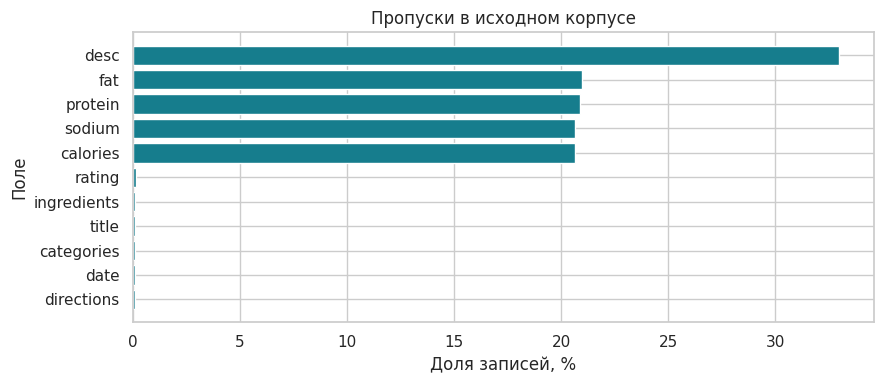

В исходных данных отсутствует 33.0% описаний. При известных категориях эти строки можно оставить для обучения тегам.


In [12]:
q=quality.sort_values('missing_pct')
plt.figure(figsize=(9,4)); plt.barh(q.field,q.missing_pct,color='#167D8D')
plt.title('Пропуски в исходном корпусе'); plt.xlabel('Доля записей, %'); plt.ylabel('Поле')
savefig('01_missing')
print(f'В исходных данных отсутствует {raw.desc.isna().mean():.1%} описаний. При известных категориях эти строки можно оставить для обучения тегам.')

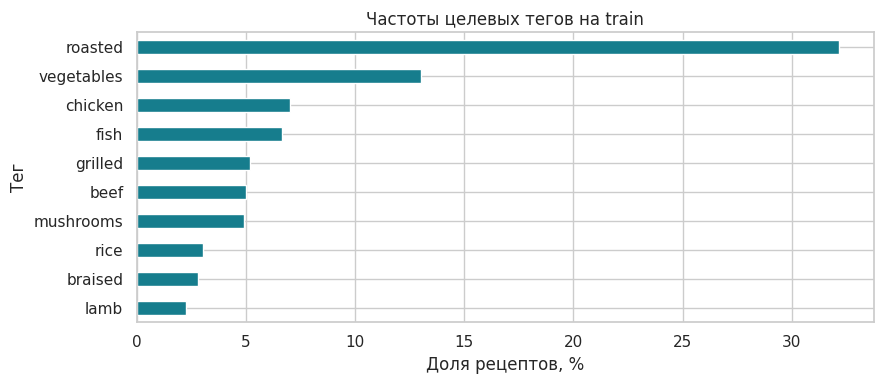

На обучении частота тега roasted=32.1%, lamb=2.3%. Из-за этой разницы результат по частым тегам может скрыть ошибки редких, поэтому считаем обе F1-метрики.


In [13]:
freq=pd.Series(ys['train'].mean(axis=0),index=LABELS).sort_values()
plt.figure(figsize=(9,4)); (100*freq).plot.barh(color='#167D8D')
plt.title('Частоты целевых тегов на train'); plt.xlabel('Доля рецептов, %'); plt.ylabel('Тег')
savefig('02_tag_frequency')
print(f'На обучении частота тега {freq.index[-1]}={freq.iloc[-1]:.1%}, {freq.index[0]}={freq.iloc[0]:.1%}. Из-за этой разницы результат по частым тегам может скрыть ошибки редких, поэтому считаем обе F1-метрики.')

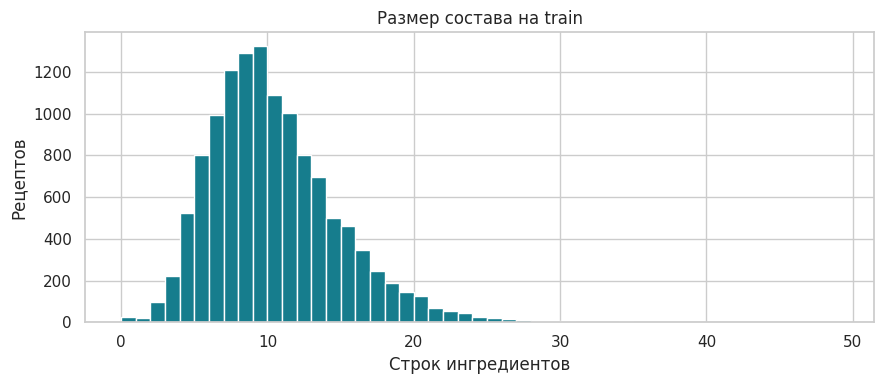

Медиана числа строк состава: 9, без состава 25 записей. Отдельная модель по названию позволит проверить сценарий без состава.


In [14]:
plt.figure(figsize=(9,4)); plt.hist(train.n_ingredients,bins=range(0,int(train.n_ingredients.max())+2),color='#167D8D')
plt.title('Размер состава на train'); plt.xlabel('Строк ингредиентов'); plt.ylabel('Рецептов')
savefig('03_ingredients')
print(f'Медиана числа строк состава: {train.n_ingredients.median():.0f}, без состава {train.n_ingredients.eq(0).sum()} записей. Отдельная модель по названию позволит проверить сценарий без состава.')

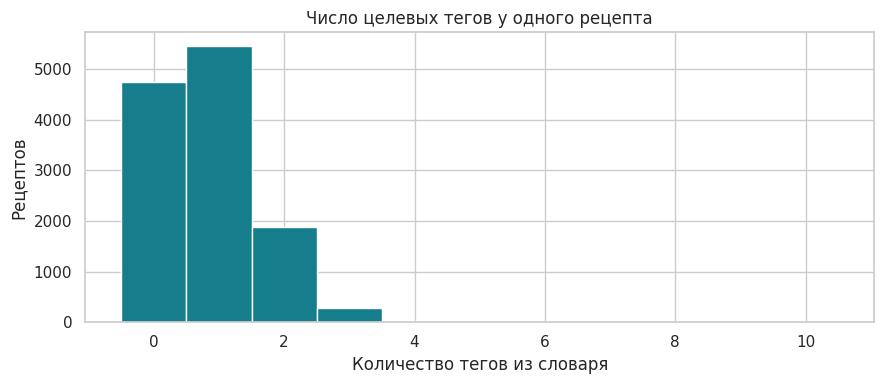

Из обучающих записей 38.4% не имеют ни одного из выбранных тегов; 17.6% имеют несколько. Поэтому число предсказанных тегов не фиксируем.


In [15]:
cardinality=ys['train'].sum(axis=1)
plt.figure(figsize=(9,4)); plt.hist(cardinality,bins=np.arange(-.5,len(LABELS)+1.5),color='#167D8D')
plt.title('Число целевых тегов у одного рецепта'); plt.xlabel('Количество тегов из словаря'); plt.ylabel('Рецептов')
savefig('04_cardinality')
print(f'Из обучающих записей {(cardinality==0).mean():.1%} не имеют ни одного из выбранных тегов; {(cardinality>1).mean():.1%} имеют несколько. Поэтому число предсказанных тегов не фиксируем.')

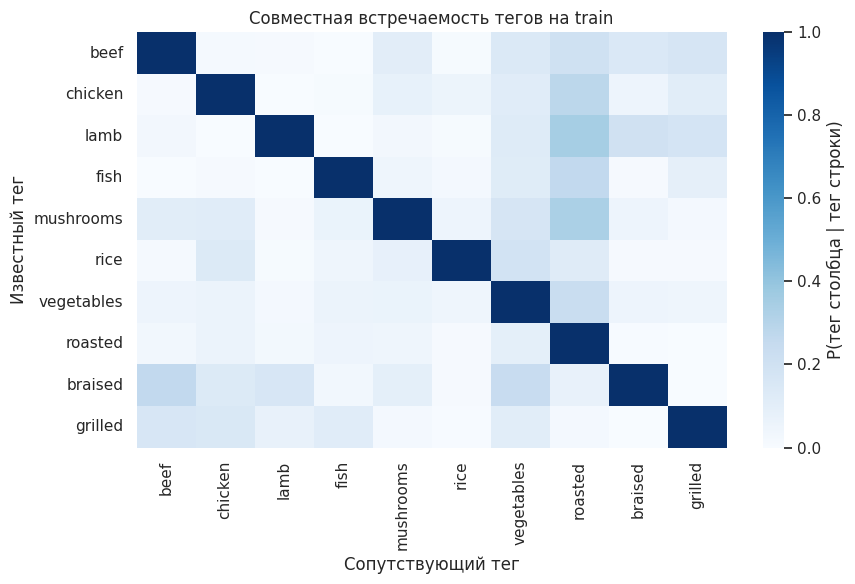

Самая высокая условная частота вне диагонали: P(roasted | lamb)=35.1%. Это показывает, какие теги часто встречаются вместе; причины такой связи здесь не проверяются.


In [16]:
y=ys['train'].astype(float); co=y.T@y; denom=np.maximum(np.diag(co)[:,None],1)
plt.figure(figsize=(9,6)); sns.heatmap(co/denom,xticklabels=LABELS,yticklabels=LABELS,cmap='Blues',vmin=0,vmax=1,cbar_kws={'label':'P(тег столбца | тег строки)'})
plt.title('Совместная встречаемость тегов на train'); plt.xlabel('Сопутствующий тег'); plt.ylabel('Известный тег')
savefig('05_cooccurrence')
masked=co/denom; np.fill_diagonal(masked,-1); i,j=np.unravel_index(masked.argmax(),masked.shape)
print(f'Самая высокая условная частота вне диагонали: P({LABELS[j]} | {LABELS[i]})={masked[i,j]:.1%}. Это показывает, какие теги часто встречаются вместе; причины такой связи здесь не проверяются.')

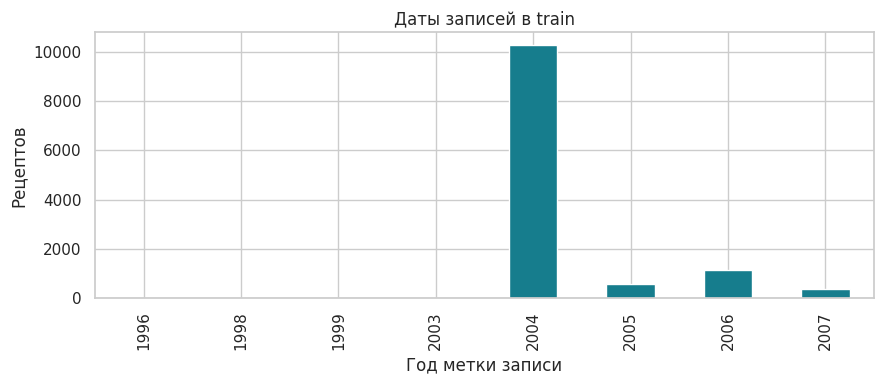

На самую частую дату приходится 80.6% train; вероятен пакетный импорт. Эти даты не описывают сезонность спроса.


,field,lower,upper,outliers_n,n
0,calories,-371.5000,1184.5000,624,10471
1,protein,-33.5000,66.5000,680,10453
2,fat,-28.5000,71.5000,732,10439
3,sodium,-849.0000,1655.0000,672,10470
4,rating,2.8125,5.3125,1137,12383
5,n_ingredients,-0.5000,19.5000,397,12383
6,desc_chars,-187.5000,312.5000,551,12383


Выбросы не удаляем автоматически: нутриенты не входят в X, а большие значения могут относиться к нескольким порциям.


In [17]:
counts=train.groupby('year').size()
plt.figure(figsize=(9,4)); counts.plot.bar(color='#167D8D')
plt.title('Даты записей в train'); plt.xlabel('Год метки записи'); plt.ylabel('Рецептов')
savefig('06_dates')
peak=train.date.dt.floor('D').value_counts().iloc[0]/len(train)
print(f'На самую частую дату приходится {peak:.1%} train; вероятен пакетный импорт. Эти даты не описывают сезонность спроса.')
outliers=[]
for field in numeric_fields+['n_ingredients','desc_chars']:
    s=train[field].dropna(); q1,q3=s.quantile([.25,.75]); lo=q1-1.5*(q3-q1); hi=q3+1.5*(q3-q1)
    outliers.append({'field':field,'lower':lo,'upper':hi,'outliers_n':int(((s<lo)|(s>hi)).sum()),'n':len(s)})
table(pd.DataFrame(outliers),'train_outliers')
print('Выбросы не удаляем автоматически: нутриенты не входят в X, а большие значения могут относиться к нескольким порциям.')

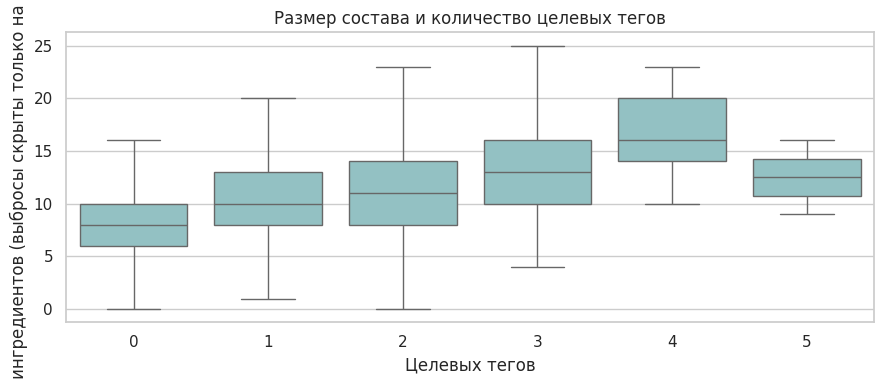

Коэффициент Spearman между размером состава и числом тегов = 0.334; длина состава сама по себе не определяет семантическую категорию.


In [18]:
label_relation=train[['n_ingredients']].copy(); label_relation['tag_count']=cardinality
plt.figure(figsize=(9,4)); sns.boxplot(data=label_relation,x='tag_count',y='n_ingredients',color='#8BC8CB',showfliers=False)
plt.title('Размер состава и количество целевых тегов'); plt.xlabel('Целевых тегов'); plt.ylabel('Строк ингредиентов (выбросы скрыты только на графике)')
savefig('07_feature_target')
corr=label_relation.corr(method='spearman').iloc[0,1]
print(f'Коэффициент Spearman между размером состава и числом тегов = {corr:.3f}; длина состава сама по себе не определяет семантическую категорию.')

## 8. Модель и способы сравнения

Для базового эксперимента выбраны TF-IDF и логистическая регрессия. TF-IDF кодирует
отдельные слова и пары слов, после чего
[OneVsRestClassifier](https://scikit-learn.org/stable/modules/multiclass.html)
обучает отдельную модель для каждого тега. Получается разреженная матрица признаков,
с которой линейная модель работает на обычном CPU. Вклад слов можно изучать по
коэффициентам, а L2-регуляризация ограничивает их величину.

Результат сравнивается с двумя простыми методами: частотами тегов на train и поиском
по заранее заданному словарю. Словарь ищет слова в названии и составе; правильные
метки берутся из категорий издателя. Ещё одна модель обучается только на названиях,
чтобы проверить, помогает ли добавление состава.

Для каждого обучаемого варианта C выбирается из `[0.5, 2]`, а порог из
`[0.2, 0.35, 0.5]`. Критерием служит micro-F1 на валидации. Модель только по названию
имеет собственное обучение и подбор параметров на тех же частях данных.

Возможными альтернативами были бы Naive Bayes, LinearSVC и многоязычный энкодер.
Naive Bayes делает сильное предположение о независимости признаков, LinearSVC
не выдаёт вероятности напрямую, а перенос энкодера на RU/KK потребовал бы отдельной
разметки. В первом эксперименте используется более простая линейная модель.

Для оценки выбраны следующие метрики:

- micro-F1 объединяет TP, FP и FN всех тегов, поэтому сильнее зависит от частых классов;
- macro-F1 усредняет F1 десяти тегов с одинаковым весом;
- micro average precision (AP) оценивает ранжирование без одного фиксированного порога;
- Hamming loss показывает долю ошибочных бинарных решений; меньшее значение лучше.

Дополнительно считается полное совпадение набора тегов для рецепта. Эти оценки
показывают согласие с разметкой издателя. Качество языка и реакция покупателя требуют
других данных и отдельной проверки.

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, average_precision_score, hamming_loss, accuracy_score, precision_recall_fscore_support
import joblib

PATTERNS={
 'beef':r'\b(beef|steak)\b','chicken':r'\bchicken\b','lamb':r'\blamb\b',
 'fish':r'\b(fish|salmon|tuna|swordfish|cod|halibut|trout)\b',
 'mushrooms':r'\b(mushrooms?|shiitake|porcini)\b','rice':r'\brice\b',
 'vegetables':r'\b(vegetables?|carrots?|tomatoes?|pumpkin|zucchini|broccoli)\b',
 'roasted':r'\b(roast\w*|bak\w*)\b','braised':r'\b(brais\w*|stew\w*)\b','grilled':r'\b(grill\w*|barbecu\w*)\b'}
def rule_predict(texts):
    return np.array([[bool(re.search(PATTERNS[tag],s,re.I)) for tag in LABELS] for s in texts],dtype=int)
def evaluate(name,y,p,threshold=.5,pred=None):
    pred=(p>=threshold).astype(int) if pred is None else pred
    return {'model':name,'micro_f1':float(f1_score(y,pred,average='micro',zero_division=0)),
      'macro_f1':float(f1_score(y,pred,average='macro',zero_division=0)),
      'micro_ap':float(average_precision_score(y,p,average='micro')),
      'hamming_loss':float(hamming_loss(y,pred)), 'exact_match':float(accuracy_score(y,pred))}

validation_rows=[]; fitted={}
for mode in ['title_and_ingredients','title_only']:
    tr=xs['train'] if mode=='title_and_ingredients' else train.title.tolist()
    va=xs['validation'] if mode=='title_and_ingredients' else val.title.tolist()
    best=None
    for C in [.5,2.]:
        pipeline=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=20000,sublinear_tf=True)),
          ('classifier',OneVsRestClassifier(LogisticRegression(C=C,solver='liblinear',max_iter=1000,random_state=SEED)))])
        started=time.perf_counter(); pipeline.fit(tr,ys['train']); elapsed=time.perf_counter()-started
        p=pipeline.predict_proba(va)
        for threshold in [.2,.35,.5]:
            result=evaluate(mode,ys['validation'],p,threshold)
            validation_rows.append({**result,'C':C,'threshold':threshold,'fit_seconds':elapsed})
            if best is None or result['micro_f1']>best['score']:
                best={'pipeline':pipeline,'C':C,'threshold':threshold,'score':result['micro_f1']}
    fitted[mode]=best
table(pd.DataFrame(validation_rows),'validation_results')
prevalence=ys['train'].mean(axis=0)
frequency_p=np.tile(prevalence,(len(val),1))
frequency_threshold=max([.05,.1,.2,.35,.5],key=lambda t:evaluate('frequency',ys['validation'],frequency_p,t)['micro_f1'])
print('Порог частотного метода:',frequency_threshold)

,model,micro_f1,macro_f1,micro_ap,hamming_loss,exact_match,C,threshold,fit_seconds
0,title_and_ingredients,0.582906,0.632072,0.619106,0.073688,0.449226,0.5,0.20,3.883312
1,title_and_ingredients,0.558252,0.467768,0.619106,0.054964,0.573801,0.5,0.35,3.883312
2,title_and_ingredients,0.446375,0.288097,0.619106,0.055342,0.574934,0.5,0.50,3.883312
3,title_and_ingredients,0.642271,0.722189,0.697715,0.064213,0.505851,2.0,0.20,4.417842
4,title_and_ingredients,0.660333,0.659277,0.697715,0.048584,0.605889,2.0,0.35,4.417842
5,title_and_ingredients,0.624306,0.577870,0.697715,0.045980,0.631182,2.0,0.50,4.417842
6,title_only,0.594883,0.673862,0.679732,0.071725,0.442431,0.5,0.20,0.544948
7,title_only,0.645952,0.616845,0.679732,0.046886,0.620612,0.5,0.35,0.544948
8,title_only,0.582236,0.518625,0.679732,0.046697,0.620234,0.5,0.50,0.544948
9,title_only,0.642138,0.701980,0.712942,0.061684,0.511514,2.0,0.20,0.681366


Порог частотного метода: 0.2


## 9. Результаты на тесте

Все методы и параметры к этому моменту определены. Ниже они сравниваются на test,
после чего рассматриваются результаты по тегам и примеры ошибок. Параметры модели
по этим ошибкам не меняются.

,model,micro_f1,macro_f1,micro_ap,hamming_loss,exact_match
0,title_and_ingredients,0.590696,0.585985,0.598738,0.049453,0.586948
1,title_only,0.614469,0.656868,0.626660,0.048849,0.586948
2,frequency,0.240271,0.031576,0.120657,0.118559,0.142210
3,dictionary,0.492407,0.618941,0.285083,0.083214,0.436816


title_and_ingredients C= 2.0 threshold= 0.35
title_only C= 2.0 threshold= 0.35


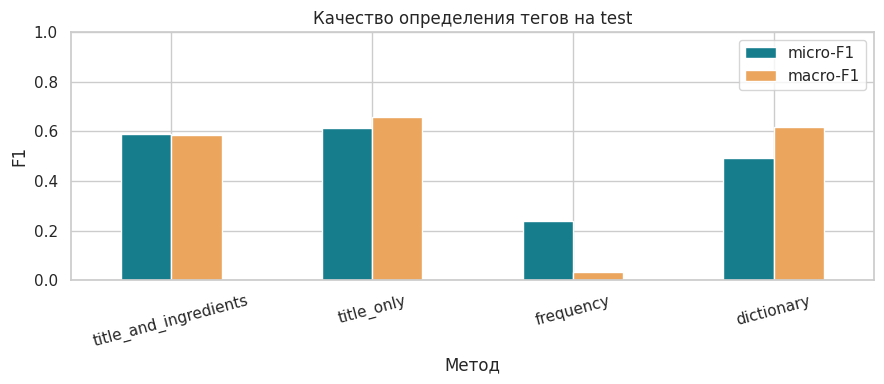

,tag,precision,recall,f1,support
0,beef,0.708738,0.695238,0.701923,105
1,chicken,0.970238,0.862434,0.913165,189
2,lamb,0.968750,0.620000,0.756098,50
3,fish,0.663934,0.669421,0.666667,121
4,mushrooms,0.761905,0.648649,0.700730,74
5,rice,0.769231,0.441176,0.560748,68
6,vegetables,0.121429,0.255639,0.164649,133
7,roasted,0.502481,0.814889,0.621642,497
8,braised,0.714286,0.158730,0.259740,63
9,grilled,0.788889,0.381720,0.514493,186


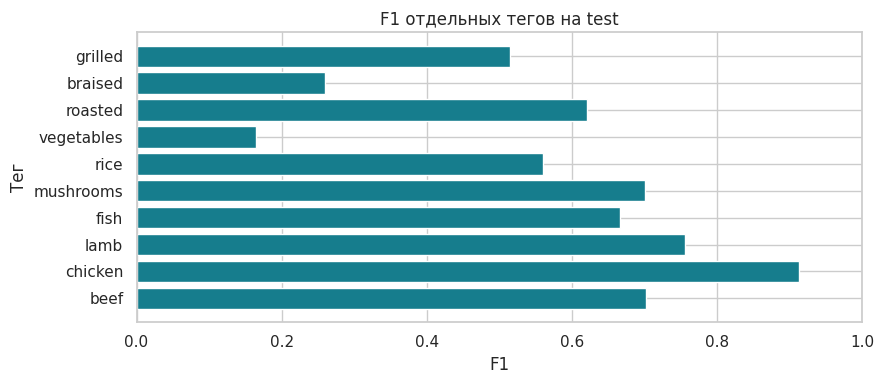

In [20]:
results=[]; probabilities={}; predictions={}
for mode,best in fitted.items():
    texts=xs['test'] if mode=='title_and_ingredients' else test.title.tolist()
    probabilities[mode]=best['pipeline'].predict_proba(texts)
    predictions[mode]=(probabilities[mode]>=best['threshold']).astype(int)
    results.append(evaluate(mode,ys['test'],probabilities[mode],best['threshold']))
probabilities['frequency']=np.tile(prevalence,(len(test),1))
predictions['frequency']=(probabilities['frequency']>=frequency_threshold).astype(int)
results.append(evaluate('frequency',ys['test'],probabilities['frequency'],frequency_threshold))
predictions['dictionary']=rule_predict(xs['test']); probabilities['dictionary']=predictions['dictionary'].astype(float)
results.append(evaluate('dictionary',ys['test'],probabilities['dictionary']))
result_df=pd.DataFrame(results); table(result_df,'test_metrics')
selected=fitted['title_and_ingredients']
bundle={'pipeline':selected['pipeline'],'threshold':selected['threshold'],'labels':LABELS,
        'tag_map':TAG_MAP,'features':['title','ingredients'],'language':'en',
        'task':'publisher recipe tags; not description effectiveness','raw_sha256':EXPECTED_SHA}
joblib.dump(bundle,ART/'models/tag_classifier.joblib')
for mode in fitted:
    print(mode,'C=',fitted[mode]['C'],'threshold=',fitted[mode]['threshold'])
plt.figure(figsize=(9,4)); result_df.set_index('model')[['micro_f1','macro_f1']].plot.bar(ax=plt.gca(),color=['#167D8D','#EBA55D'])
plt.title('Качество определения тегов на test'); plt.xlabel('Метод'); plt.ylabel('F1'); plt.ylim(0,1); plt.xticks(rotation=15)
plt.legend(['micro-F1','macro-F1']); savefig('08_models')
precision,recall,fscore,count=precision_recall_fscore_support(ys['test'],predictions['title_and_ingredients'],zero_division=0)
per_label=pd.DataFrame({'tag':LABELS,'precision':precision,'recall':recall,'f1':fscore,'support':count})
table(per_label,'per_label_metrics')
plt.figure(figsize=(9,4)); plt.barh(LABELS,fscore,color='#167D8D'); plt.xlim(0,1)
plt.title('F1 отдельных тегов на test'); plt.xlabel('F1'); plt.ylabel('Тег'); savefig('09_per_tag')

In [21]:
# Парный bootstrap по рецептам: одинаковые индексы для обоих методов.
# Интервал условен на одном fit и не учитывает вариативность обучения.
ytest=ys['test']; learned=predictions['title_and_ingredients']; base=predictions['frequency']
def contributions(pred):
    return np.column_stack(((pred*ytest).sum(axis=1), (pred*(1-ytest)).sum(axis=1), ((1-pred)*ytest).sum(axis=1)))
a,b=contributions(learned),contributions(base)
def micro_from(v):
    tp,fp,fn=v; return 2*tp/max(2*tp+fp+fn,1)
rng=np.random.default_rng(SEED); delta=[]
for _ in range(1000):
    idx=rng.integers(0,len(test),len(test)); delta.append(micro_from(a[idx].sum(axis=0))-micro_from(b[idx].sum(axis=0)))
ci=np.quantile(delta,[.025,.975]).tolist()
errors=[]
for pos,(_,row) in enumerate(test.iterrows()):
    wrong=np.flatnonzero(learned[pos]!=ytest[pos])
    if len(wrong):
        errors.append({'source_id':int(row.source_id),'title':row.title,'ingredients':row.ingredients,
          'true_tags':[LABELS[i] for i in np.flatnonzero(ytest[pos])],
          'predicted_tags':[LABELS[i] for i in np.flatnonzero(learned[pos])],
          'wrong_tags':[LABELS[i] for i in wrong],'error_count':len(wrong)})
errors_df=pd.DataFrame(errors).sort_values(['error_count','source_id'],ascending=[False,True])
errors_df.to_csv(ART/'tables/error_examples.csv',index=False,encoding='utf-8-sig')
display(errors_df.head(8))
pd.DataFrame({'source_id':test.source_id,'true_tags':[[LABELS[i] for i in np.flatnonzero(row)] for row in ytest],
              'predicted_tags':[[LABELS[i] for i in np.flatnonzero(row)] for row in learned]}).to_csv(ART/'tables/test_predictions.csv',index=False,encoding='utf-8-sig')
best_tag=per_label.sort_values('f1',ascending=False).iloc[0]; worst_tag=per_label.sort_values('f1').iloc[0]
by=result_df.set_index('model'); gain=float(by.loc['title_and_ingredients','micro_f1']-by.loc['frequency','micro_f1'])
title_loss=float(by.loc['title_and_ingredients','micro_f1']-by.loc['title_only','micro_f1'])
observations=[
 f'RQ1: {len(raw)} исходных → {len(clean)} после очистки → {len(supervised)} с категориями и датой. Полных дубликатов {exact_duplicates}.',
 f'RQ1: {raw.desc.isna().mean():.1%} исходных desc отсутствуют; они не нужны для target=категории. Частоты тегов train: {freq.iloc[0]:.1%}–{freq.iloc[-1]:.1%}.',
 f'RQ2: micro-F1 обученного метода {by.loc["title_and_ingredients","micro_f1"]:.3f}, частотного {by.loc["frequency","micro_f1"]:.3f}, словаря {by.loc["dictionary","micro_f1"]:.3f}.',
 f'H1: Δmicro-F1={gain:.3f}; 95% bootstrap [{ci[0]:.3f}; {ci[1]:.3f}]. Вывод относится к категориям этого корпуса.',
 f'RQ3: title-only micro-F1={by.loc["title_only","micro_f1"]:.3f}; разность full−title={title_loss:.3f}.',
 f'Лучший тег {best_tag.tag}: F1={best_tag.f1:.3f}; слабейший {worst_tag.tag}: F1={worst_tag.f1:.3f}. Редкость, неоднозначность и отсутствие метода в X затрудняют часть меток.',
 'Следующий эксперимент: ручная разметка тегов упоминаний на независимых RU/KK-описаниях. Для эффективности нужны реальные показы и реакция, а затем рандомизированное сравнение выдачи.'
]
for item in observations: display(Markdown('- '+item))
metrics={'raw_rows':len(raw),'raw_columns':len(raw.columns),'raw_bytes':len(payload),'raw_sha256':EXPECTED_SHA,
 'exact_duplicates':exact_duplicates,'clean_rows':len(clean),'labelled_rows':len(supervised),
 'missing_desc':int(raw.desc.isna().sum()),'split':split_summary.to_dict('records'),
 'tag_count':len(LABELS),'test':results,'selected_C':selected['C'],'selected_threshold':selected['threshold'],
 'micro_f1_gain_over_frequency':gain,'gain_ci95':ci,'full_minus_title':title_loss,
 'observations':observations,'best_tag':best_tag.to_dict(),'worst_tag':worst_tag.to_dict(),
 'peak_day_share_train':float(peak),'zero_label_share_train':float((cardinality==0).mean()),
 'package_versions':{p:metadata.version(p) for p in PINS},'python':platform.python_version(),
 'real_conversion_data':False,'scope':'EN publisher-tag baseline; RU/KK and business lift unverified'}
(ART/'metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')
print('Сохранены реальные результаты обучения и модель:',ART/'models/tag_classifier.joblib')

,source_id,title,ingredients,true_tags,predicted_tags,wrong_tags,error_count
123,468,Tatemado de Costilla de Res (Tatemado Short Ribs),"[4 (3-inch cut) short ribs, 8 ancho chiles, veins removed and seeded, 1 pound oni...","[beef, braised]",[roasted],"[beef, roasted, braised]",3
837,1272,Roasted Short Ribs With Cauliflower And Celery,"[4 cloves garlic, Kosher salt, 1 tablespoon chopped rosemary, 1 tablespoon olive ...","[beef, braised]","[beef, vegetables, roasted]","[vegetables, roasted, braised]",3
843,1519,"Stuffed Lamb Breast With Lemon, Ricotta, And Oregano","[2 teaspoons dried oregano, 2 teaspoons fennel seeds, 1 teaspoon crushed red pepp...","[lamb, braised]",[roasted],"[lamb, roasted, braised]",3
947,1970,Red Curry–Marinated Japanese Eggplant,"[6 Fresno chiles, seeds removed from 3, chopped, 4 garlic cloves, 2 lemongrass st...",[grilled],"[vegetables, roasted]","[vegetables, roasted, grilled]",3
629,2041,Lamb-Bacon Burgers with Spicy Aioli,"[1 large egg yolk*, 2 teaspoons Dijon mustard, 1/2 cup vegetable oil, 1 canned ch...","[lamb, grilled]",[roasted],"[lamb, roasted, grilled]",3
589,2140,Beef Bourguignonne Pot Pie,"[3 tablespoons olive oil, 1/2 cup plus 1 tablespoon all-purpose flour, plus more,...","[vegetables, roasted]","[beef, mushrooms, roasted]","[beef, mushrooms, vegetables]",3
254,2607,Easy Arancini,"[1 ounce mixed dried wild mushrooms, Butter, Flavorless oil, such as peanut, 1 sm...","[mushrooms, rice]",[roasted],"[mushrooms, rice, roasted]",3
539,3149,My Chicken Broth-Braised Baby Turnips,"[14 ounces small new turnips, all about the same size for even cooking, peeled, 1...",[vegetables],"[chicken, roasted]","[chicken, vegetables, roasted]",3


- RQ1: 20130 исходных → 17722 после очистки → 17683 с категориями и датой. Полных дубликатов 1834.

- RQ1: 33.0% исходных desc отсутствуют; они не нужны для target=категории. Частоты тегов train: 2.3%–32.1%.

- RQ2: micro-F1 обученного метода 0.591, частотного 0.240, словаря 0.492.

- H1: Δmicro-F1=0.350; 95% bootstrap [0.329; 0.372]. Вывод относится к категориям этого корпуса.

- RQ3: title-only micro-F1=0.614; разность full−title=-0.024.

- Лучший тег chicken: F1=0.913; слабейший vegetables: F1=0.165. Редкость, неоднозначность и отсутствие метода в X затрудняют часть меток.

- Следующий эксперимент: ручная разметка тегов упоминаний на независимых RU/KK-описаниях. Для эффективности нужны реальные показы и реакция, а затем рандомизированное сравнение выдачи.

Сохранены реальные результаты обучения и модель: C:\Users\ARYSLAN Kurmetov\MenuMind\MenuMind\experiments\tags-midterm\artifacts\models\tag_classifier.joblib


## 10. Как теги используются в приложении

В составе блюда могут быть курица и рис, но описание «Блюдо в меню» не упоминает
ни один из этих ингредиентов. Для персонализации полезно учитывать именно содержание
выбранного текста. Поэтому API хранит отдельно теги карточки и теги упоминаний.
У каждого упоминания есть фрагмент текста и ссылка на соответствующий факт карточки.
Теги пересчитываются для каждого канала, а краткость определяется по длине текста.

Внешняя LLM создаёт варианты описания, затем сервер проверяет их и извлекает теги
по словарю. Поле `requestedStyle` хранит запрошенный стиль (`concise`, `ingredients`
или `method`); само по себе оно не подтверждает, какой акцент получился в тексте.
Обученная в этом notebook модель сохранена для экспериментов с английскими
категориями и не используется как источник новых фактов при генерации RU/KK.

Описание выбирает [LinUCB](https://arxiv.org/abs/1003.0146). Его признаки включают
предпочтения гостя, теги карточки и конкретного варианта, язык, канал и историю
до текущего показа. Оценка LinUCB складывается из ожидаемой награды и бонуса за
неопределённость, поэтому она не равна вероятности покупки.

После подтверждённого показа система ждёт добавления в корзину в течение 30 минут.
Такое действие даёт награду 1, истечение окна без действия даёт 0. Если текст не был
показан, отрицательный пример не создаётся. Один показ учитывается один раз,
тестовые и рабочие реакции хранятся отдельно. Чтобы измерить пользу персонализации,
понадобятся реальные логи и сравнение с контрольной выдачей.

## 11. Ограничения и продолжение работы

Главное ограничение связано с разметкой: категории издателя не всегда перечисляют
все свойства рецепта. Отрицательная метка поэтому может означать пропущенный тег.
Разбиение по датам и группам снижает риск пересечения выборок, но не исключает
близкие перефразы; одинаковый состав, наоборот, мог привести к удалению разных блюд.
Корпус ранее изучался в проекте. Bootstrap-интервал относится к одной обученной
модели и не учитывает вариативность повторного обучения на других данных.

Следующий эксперимент требует новых описаний на русском и казахском с ручной
разметкой упоминаний. На них можно проверить перенос и сравнить словарь с моделями.
Теги аллергенов не входят в текущий классификатор; отсутствие такого тега не
позволяет сделать вывод о безопасности блюда. Для приёмки генерации отдельно
нужно проверить 30 позиций заказчика по `10.docx`.

## 12. Где находятся материалы работы

| Материал | Раздел или файл |
|---|---|
| Постановка, вопросы, гипотеза и источник | Разделы 1–2 |
| Структура, качество данных и очистка до/после | Разделы 3–4, таблицы CSV |
| Признаки, target, утечка и разделение | Разделы 5–6 |
| EDA и семь графиков | Раздел 7 |
| Обучение и выбор модели | Раздел 8, сохранённый joblib |
| Метрики, два графика результатов и ошибки | Раздел 9 |
| Связь с приложением и ограничения | Разделы 10–11 |
| Двухстраничный отчёт | `MenuMind_report.pdf` и `.docx` |
| Семь слайдов и текст выступления | `MenuMind_presentation.pptx`, `speaker_notes.txt` |